In [ ]:
# ============================================================
# DATA QUALITY & CLEANING PROJECT
# Dataset: LendingClub Accepted 50K
# Jupyter Notebook - ONE CELL VERSION (portable paths)
# ============================================================

# 1. IMPORT LIBRARIES
import os
import warnings
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)

# ============================================================
# 2. USER SETTINGS  <-- EDIT ONLY THIS BLOCK
# ============================================================
# All paths below are RELATIVE to the project folder, so the
# code works on any device without changes.

REPO_FOLDER_NAME    = "DEPI-ITC-ONL5-DA-Team3-G3-Projects"   # repo (git clone) folder
PROJECT_FOLDER_NAME = "FinalProject"                         # folder holding all the work

# Optional: set a full path ONLY if auto-detection fails on some machine.
# Leave as None normally.   Example: PROJECT_DIR_OVERRIDE = r"D:\my\FinalProject"
PROJECT_DIR_OVERRIDE = None

# --- INPUT: which file to pick, and where it lives ---
INPUT_SUBDIR    = Path("data") / "Sampled"
INPUT_FILE_NAME = "validation_sample_accepted_2007_to_2018Q4.csv"

# --- OUTPUT: where to write results ---
CLEANED_SUBDIR    = Path("data") / "Cleaned" / "Validation"
CLEANED_FILE_NAME = "accepted_cleaned.csv"

REPORT_SUBDIR      = Path("docs") / "Data Cleaning" / "Validation"
DATASET_REPORT_NAME = "Accepted"                      # sub-folder inside the report folder
GUIDE_FILE_NAME     = "Accepted_Cleaning_Guide.md"

# ============================================================
# 3. RESOLVE PROJECT ROOT AUTOMATICALLY
# ============================================================

def find_project_dir(project_name, repo_name, override=None):
    """
    Finds the project folder no matter where the notebook is running from:
      - inside FinalProject (or any sub-folder of it)
      - at the repo root
      - in a folder next to / above the repo
    """
    if override:
        p = Path(override).expanduser().resolve()
        if not p.is_dir():
            raise FileNotFoundError(f"PROJECT_DIR_OVERRIDE does not exist: {p}")
        return p

    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        # case 1: we are inside FinalProject
        if p.name == project_name:
            return p
        # case 2: FinalProject is a direct child (e.g. we are at the repo root)
        if (p / project_name).is_dir():
            return p / project_name
        # case 3: repo folder is a child of this folder
        if (p / repo_name / project_name).is_dir():
            return p / repo_name / project_name

    raise FileNotFoundError(
        f"Could not find a '{project_name}' folder starting from: {start}\n"
        f"Open the notebook inside the '{repo_name}' repo, "
        "or set PROJECT_DIR_OVERRIDE in the settings block."
    )

PROJECT_DIR = find_project_dir(PROJECT_FOLDER_NAME, REPO_FOLDER_NAME, PROJECT_DIR_OVERRIDE)

# ============================================================
# 3.1 BUILD ALL PATHS FROM THE SETTINGS
# ============================================================

INPUT_DIR   = PROJECT_DIR / INPUT_SUBDIR
CLEANED_DIR = PROJECT_DIR / CLEANED_SUBDIR
REPORT_ROOT = PROJECT_DIR / REPORT_SUBDIR

DATASET_REPORT_DIR = REPORT_ROOT / DATASET_REPORT_NAME
BEFORE_DIR  = DATASET_REPORT_DIR / "Before_Cleaning"
AFTER_DIR   = DATASET_REPORT_DIR / "After_Cleaning"
REPORT_DIR  = DATASET_REPORT_DIR

FILE_PATH    = INPUT_DIR / INPUT_FILE_NAME
CLEANED_FILE = CLEANED_DIR / CLEANED_FILE_NAME
GUIDE_FILE   = REPORT_ROOT / GUIDE_FILE_NAME

for folder in [CLEANED_DIR, REPORT_ROOT, DATASET_REPORT_DIR, BEFORE_DIR, AFTER_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Convert to plain strings so any later code using os.path / string
# concatenation keeps working exactly as before.
(PROJECT_DIR, INPUT_DIR, CLEANED_DIR, REPORT_ROOT, DATASET_REPORT_DIR,
 BEFORE_DIR, AFTER_DIR, REPORT_DIR, FILE_PATH, CLEANED_FILE, GUIDE_FILE) = map(
    str,
    (PROJECT_DIR, INPUT_DIR, CLEANED_DIR, REPORT_ROOT, DATASET_REPORT_DIR,
     BEFORE_DIR, AFTER_DIR, REPORT_DIR, FILE_PATH, CLEANED_FILE, GUIDE_FILE),
)

print("Project root :", PROJECT_DIR)
print("Input file   :", FILE_PATH)
print("Cleaned file :", CLEANED_FILE)
print("Reports dir  :", REPORT_DIR)

# ============================================================
# 3.2 LOAD RAW DATA
# ============================================================

def load_data(file_path):
    if not os.path.exists(file_path):
        available = (
            sorted(p.name for p in Path(file_path).parent.glob("*.csv"))
            if Path(file_path).parent.exists() else []
        )
        raise FileNotFoundError(
            f"File not found: {file_path}\n"
            f"CSV files found in that folder: {available if available else 'none'}\n"
            "Fix INPUT_SUBDIR / INPUT_FILE_NAME in the settings block."
        )

    try:
        return pd.read_csv(file_path, low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(file_path, encoding="cp1252", low_memory=False)

raw_df = load_data(FILE_PATH)
df = raw_df.copy(deep=True)

print("\nDATA LOADED SUCCESSFULLY")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

try:
    display(df.head())      # Jupyter
except NameError:
    print(df.head())        # plain Python fallback

Project root : G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject
Input file   : G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\data\Sampled\validation_sample_accepted_2007_to_2018Q4.csv
Cleaned file : G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\data\Cleaned\accepted_cleaned.csv
Reports dir  : G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\docs\Data Cleaning\Accepted

DATA LOADED SUCCESSFULLY
Rows: 50000
Columns: 151


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68476702,NaN,28000.0,28000.0,28000.0,36 months,13.44,949.38,C,C3,Director of Product Development,2 years,OWN,125000.0,Source Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,100xx,NY,7.49,0.0,May-2000,695.0,699.0,0.0,NaN,NaN,6.0,0.0,22780.0,63.1,22.0,w,0.0,0.0,33320.393324,33320.39,28000.00,5320.39,0.00,0.0,0.000,Dec-2017,12486.30,NaN,Mar-2019,744.0,740.0,0.0,NaN,1.0,Individual,NaN,NaN,NaN,0.0,0.0,22780.0,0.0,0.0,0.0,0.0,64.0,0.0,NaN,0.0,1.0,6881.0,63.0,36100.0,0.0,0.0,1.0,1.0,3797.0,10607.0,63.4,0.0,0.0,113.0,187.0,22.0,22.0,0.0,22.0,NaN,10.0,NaN,0.0,4.0,4.0,5.0,10.0,3.0,6.0,19.0,5.0,6.0,0.0,0.0,0.0,0.0,100.0,40.0,0.0,0.0,36100.0,22780.0,29000.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68436934,NaN,23975.0,23975.0,23975.0,60 months,19.89,633.73,E,E3,Principal,10+ years,RENT,70000.0,Not Verified,Dec-2015,Charged Off,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,credit_card,Credit card refinancing,220xx,VA,33.20,0.0,Jun-1995,685.0,689.0,1.0,NaN,NaN,10.0,0.0,44807.0,94.9,19.0,w,0.0,0.0,3928.860000,3928.86,1478.13,2450.73,0.00,0.0,0.000,Jul-2016,633.73,NaN,Feb-2017,519.0,515.0,0.0,NaN,1.0,Individual,NaN,NaN,NaN,0.0,0.0,57655.0,1.0,1.0,0.0,1.0,24.0,6234.0,30.0,1.0,1.0,9973.0,77.0,47200.0,0.0,0.0,1.0,2.0,6406.0,1249.0,97.2,0.0,0.0,24.0,240.0,4.0,4.0,3.0,52.0,NaN,4.0,NaN,0.0,5.0,7.0,6.0,7.0,1.0,8.0,14.0,7.0,10.0,0.0,0.0,0.0,1.0,100.0,100.0,0.0,0.0,74779.0,57655.0,44400

In [2]:

# ============================================================
# 4. BASIC DATA INFORMATION
# ============================================================

print("\nDATASET INFORMATION")
print("Shape:", df.shape)

print("\nData Types:")
display(df.dtypes.astype(str))

print("\nStatistical Description:")
display(df.describe(include="all").T)

print("\nDuplicate Rows:", int(df.duplicated().sum()))

print(
    "Memory Usage:",
    round(df.memory_usage(deep=True).sum() / 1024**2, 2),
    "MB"
)

# ============================================================
# 5. BASIC QUALITY PROFILE
# ============================================================

quality_profile = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().mean().values * 100
    ).round(2),
    "Unique_Values": df.nunique(dropna=True).values
}).sort_values("Missing_Percentage", ascending=False)

quality_profile.to_csv(
    os.path.join(REPORT_DIR, "Quality_Profile.csv"),
    index=False
)

display(quality_profile)




DATASET INFORMATION
Shape: (50000, 151)

Data Types:


id                        object
member_id                float64
loan_amnt                float64
funded_amnt              float64
funded_amnt_inv          float64
                          ...   
settlement_status         object
settlement_date           object
settlement_amount        float64
settlement_percentage    float64
settlement_term          float64
Length: 151, dtype: object


Statistical Description:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,50000,50000,68476702,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
member_id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,49999.0,NaN,NaN,NaN,14969.612392,9172.493752,1000.0,8000.0,12600.0,20000.0,40000.0
funded_amnt,49999.0,NaN,NaN,NaN,14966.298826,9172.165918,1000.0,8000.0,12600.0,20000.0,40000.0
funded_amnt_inv,49999.0,NaN,NaN,NaN,14948.724251,9173.891961,0.0,8000.0,12600.0,20000.0,40000.0
...,...,...,...,...,...,...,...,...,...,...,...
settlement_status,736,3,ACTIVE,334,NaN,NaN,NaN,NaN,NaN,NaN,NaN
settlement_date,736,57,Jan-2019,49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
settlement_amount,736.0,NaN,NaN,NaN,4847.188003,3517.760894,120.0,2188.6475,4178.27,6753.25,21375.35
settlement_percentage,736.0,NaN,NaN,NaN,48.02072,7.013629,20.0,45.0,45.0,50.0,100.0



Duplicate Rows: 0
Memory Usage: 132.55 MB


,Column,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
1,member_id,float64,50000,100.00,0
140,orig_projected_additional_accrued_interest,float64,49813,99.63,186
135,hardship_end_date,object,49755,99.51,25
134,hardship_start_date,object,49755,99.51,23
129,hardship_type,object,49755,99.51,1
...,...,...,...,...,...
34,revol_bal,float64,1,0.00,26712
28,fico_range_high,float64,1,0.00,44
27,fico_range_low,float64,1,0.00,44
23,addr_state,object,1,0.00,50


,Column,Null_Count,Null_Percentage
1,member_id,50000,100.00
140,orig_projected_additional_accrued_interest,49813,99.63
135,hardship_end_date,49755,99.51
134,hardship_start_date,49755,99.51
129,hardship_type,49755,99.51
...,...,...,...
34,revol_bal,1,0.00
28,fico_range_high,1,0.00
27,fico_range_low,1,0.00
23,addr_state,1,0.00


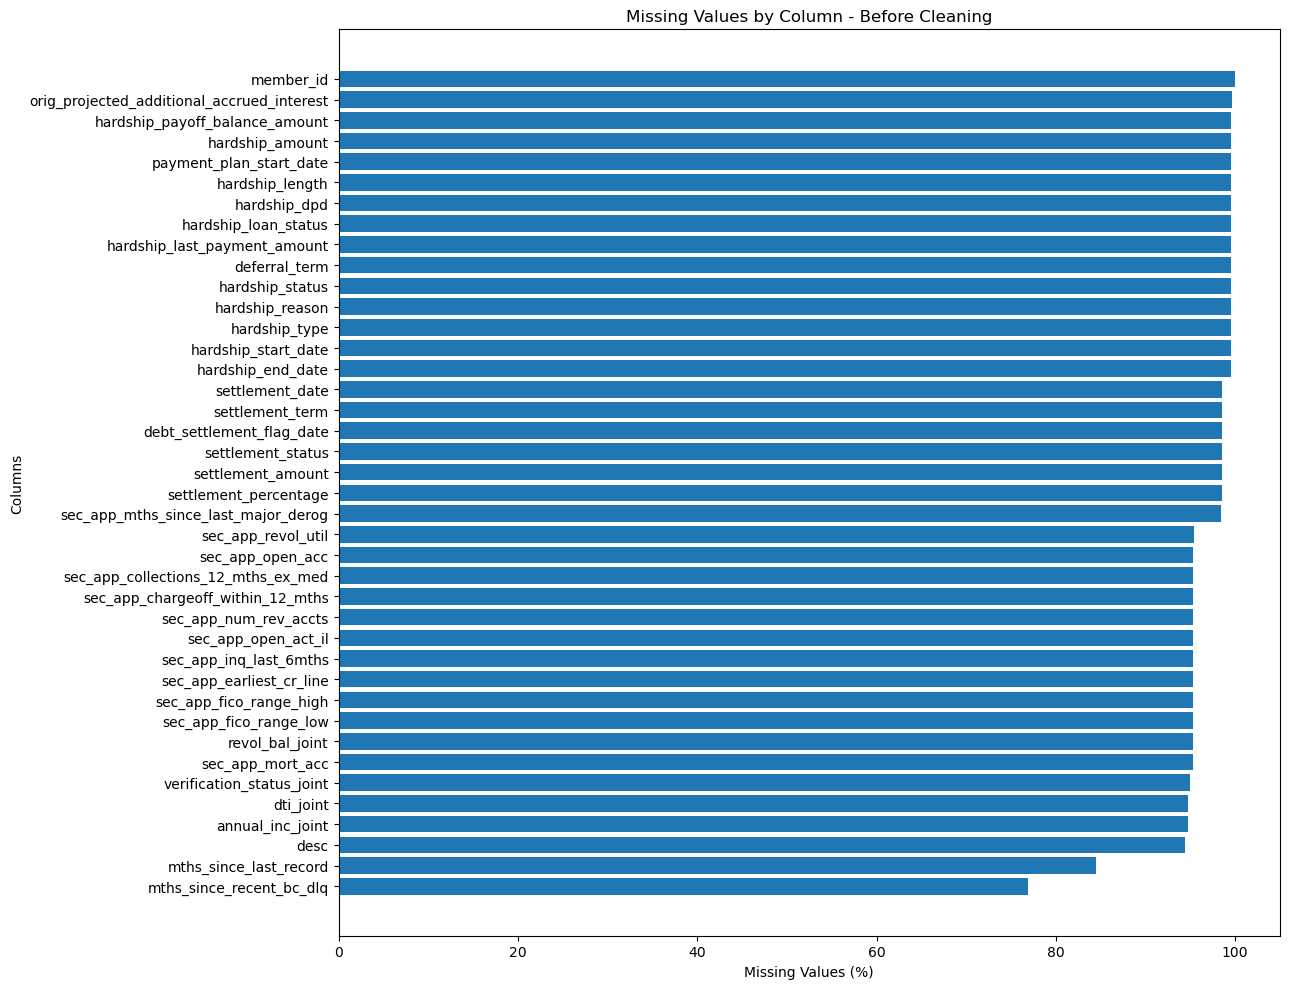

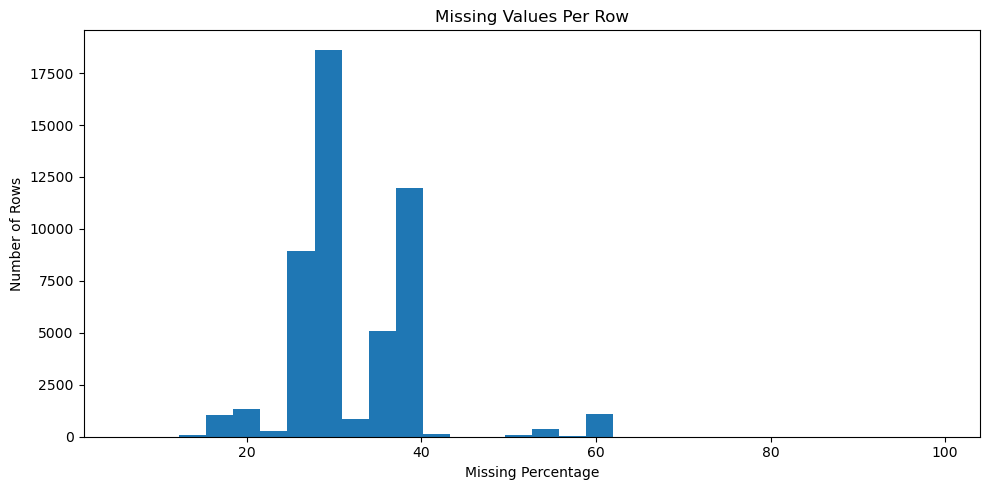

,Column_1,Column_2,Both_Missing,Jaccard_Similarity,Missing_Correlation
0,member_id,emp_title,3690,0.07380,NaN
1,member_id,emp_length,3218,0.06436,NaN
2,member_id,desc,47206,0.94412,NaN
3,member_id,title,506,0.01012,NaN
4,member_id,dti,41,0.00082,NaN
5,member_id,mths_since_last_delinq,25651,0.51302,NaN
6,member_id,mths_since_last_record,42221,0.84442,NaN
7,member_id,revol_util,46,0.00092,NaN
8,member_id,last_pymnt_d,54,0.00108,NaN
9,member_id,next_pymnt_d,29754,0.59508,NaN


In [3]:

# ============================================================
# OBJECTIVE 1: GRAPHS BEFORE CLEANING
# ============================================================

# ============================================================
# 6. NULL VALUES ANALYSIS
# ============================================================

null_report = pd.DataFrame({
    "Column": df.columns,
    "Null_Count": df.isnull().sum().values,
    "Null_Percentage": (
        df.isnull().mean().values * 100
    ).round(2)
}).sort_values("Null_Percentage", ascending=False)

null_report.to_csv(
    os.path.join(REPORT_DIR, "Null_Report_Before.csv"),
    index=False
)

display(null_report)

top_nulls = (
    null_report[null_report["Null_Count"] > 0]
    .head(40)
    .sort_values("Null_Percentage")
)

plt.figure(figsize=(13, 10))

if not top_nulls.empty:
    plt.barh(
        top_nulls["Column"],
        top_nulls["Null_Percentage"]
    )
    plt.title("Missing Values by Column - Before Cleaning")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Columns")
else:
    plt.text(0.5, 0.5, "No Missing Values Found",
             ha="center", va="center")
    plt.axis("off")

plt.tight_layout()
plt.savefig(
    os.path.join(BEFORE_DIR, "Null_Values.png"),
    dpi=160
)
plt.show()
plt.close()

# Missing values per row
row_missing_percentage = df.isnull().mean(axis=1) * 100

plt.figure(figsize=(10, 5))
plt.hist(row_missing_percentage, bins=30)
plt.title("Missing Values Per Row")
plt.xlabel("Missing Percentage")
plt.ylabel("Number of Rows")
plt.tight_layout()
plt.savefig(
    os.path.join(BEFORE_DIR, "Row_Missingness.png"),
    dpi=160
)
plt.show()
plt.close()

# ============================================================
# 7. CO-MISSING COLUMNS
# ============================================================

def analyze_comissing(data):
    columns = data.columns[data.isnull().any()].tolist()
    results = []

    for col1, col2 in combinations(columns, 2):
        missing1 = data[col1].isnull()
        missing2 = data[col2].isnull()

        both_missing = int((missing1 & missing2).sum())
        union = int((missing1 | missing2).sum())

        if both_missing >= 5 and union > 0:
            correlation = missing1.astype(int).corr(
                missing2.astype(int)
            )

            results.append({
                "Column_1": col1,
                "Column_2": col2,
                "Both_Missing": both_missing,
                "Jaccard_Similarity": both_missing / union,
                "Missing_Correlation": correlation
            })

    return pd.DataFrame(
        results,
        columns=[
            "Column_1",
            "Column_2",
            "Both_Missing",
            "Jaccard_Similarity",
            "Missing_Correlation"
        ]
    )

comissing_report = analyze_comissing(df)

comissing_report.to_csv(
    os.path.join(REPORT_DIR, "Co_Missing_Columns.csv"),
    index=False
)

display(comissing_report.head(50))


,Column,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage,Minimum,Maximum
0,last_pymnt_amnt,-4904.83750,8998.022500,6884,13.768275,0.00,4.079829e+04
1,inq_fi,-1.50000,2.500000,3845,12.435719,0.00,2.700000e+01
2,settlement_percentage,37.50000,57.500000,88,11.956522,20.00,1.000000e+02
3,out_prncp_inv,-9180.35250,15300.587500,4739,9.478190,0.00,3.948454e+04
4,out_prncp,-9184.62000,15307.700000,4736,9.472189,0.00,3.948454e+04
5,open_acc_6m,-1.50000,2.500000,2922,9.450500,0.00,1.000000e+01
6,mths_since_rcnt_il,-18.50000,49.500000,2654,8.868839,0.00,4.110000e+02
7,mths_since_recent_bc,-30.00000,66.000000,4229,8.749897,0.00,6.560000e+02
8,bc_open_to_buy,-16850.50000,32665.500000,4025,8.333851,0.00,2.593750e+05
9,open_act_il,-2.00000,6.000000,2551,8.250590,0.00,3.400000e+01


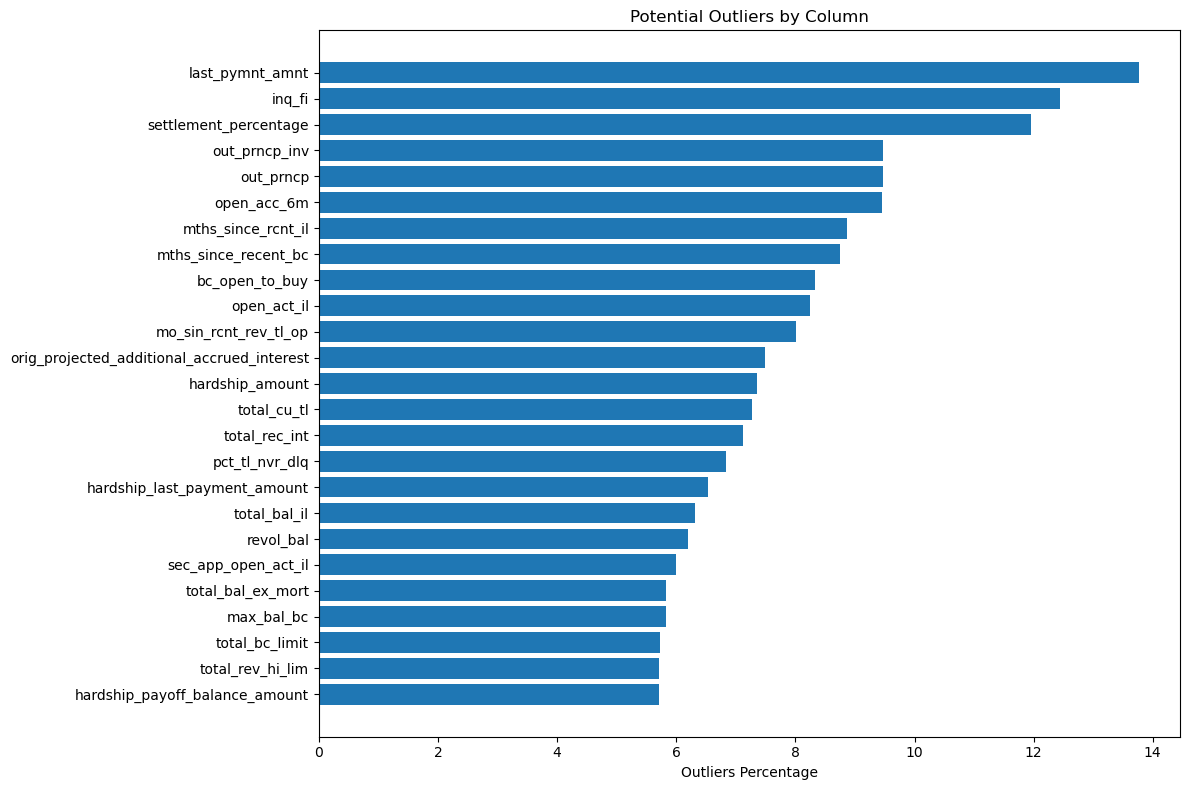

In [4]:

# ============================================================
# 8. OUTLIERS ANALYSIS
# ============================================================

OUTLIER_COLUMNS = [
    "Column",
    "Lower_Bound",
    "Upper_Bound",
    "Outlier_Count",
    "Outlier_Percentage",
    "Minimum",
    "Maximum"
]

def detect_outliers(data):
    numeric_data = data.select_dtypes(include=[np.number])
    results = []

    for column in numeric_data.columns:
        values = numeric_data[column].dropna()

        if len(values) < 10 or values.nunique() <= 2:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        if pd.isna(iqr):
            continue

        if iqr == 0:
            lower = values.quantile(0.01)
            upper = values.quantile(0.99)
        else:
            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr

        outlier_mask = (values < lower) | (values > upper)

        results.append({
            "Column": column,
            "Lower_Bound": lower,
            "Upper_Bound": upper,
            "Outlier_Count": int(outlier_mask.sum()),
            "Outlier_Percentage": float(outlier_mask.mean() * 100),
            "Minimum": values.min(),
            "Maximum": values.max()
        })

    return (
        pd.DataFrame(results, columns=OUTLIER_COLUMNS)
        .sort_values("Outlier_Percentage", ascending=False)
        .reset_index(drop=True)
    )

outlier_report = detect_outliers(df)

outlier_report.to_csv(
    os.path.join(REPORT_DIR, "Outliers_Report.csv"),
    index=False
)

display(outlier_report.head(50))

top_outliers = (
    outlier_report.head(25)
    .sort_values("Outlier_Percentage")
)

plt.figure(figsize=(12, 8))

if not top_outliers.empty:
    plt.barh(
        top_outliers["Column"],
        top_outliers["Outlier_Percentage"]
    )
    plt.title("Potential Outliers by Column")
    plt.xlabel("Outliers Percentage")
else:
    plt.text(0.5, 0.5, "No Eligible Numeric Columns",
             ha="center", va="center")
    plt.axis("off")

plt.tight_layout()
plt.savefig(
    os.path.join(BEFORE_DIR, "Outliers_Graph.png"),
    dpi=160
)
plt.show()
plt.close()


In [5]:

# ============================================================
# 9. INCONSISTENT CATEGORIES
# ============================================================

CATEGORY_COLUMNS = [
    "Column",
    "Normalized_Value",
    "Original_Variants",
    "Number_Of_Variants"
]

def find_category_variants(data):
    results = []

    categorical_columns = data.select_dtypes(
        include=["object", "string", "category"]
    ).columns

    for column in categorical_columns:
        values = data[column].dropna().astype(str)

        unique_count = values.nunique()

        if unique_count < 2 or unique_count > 100:
            continue

        normalized = values.str.strip().str.casefold()

        groups = pd.DataFrame({
            "Original": values.to_numpy(),
            "Normalized": normalized.to_numpy()
        })

        grouped = groups.groupby("Normalized")["Original"].agg(
            lambda x: sorted(set(x))
        )

        for key, variants in grouped.items():
            if len(variants) > 1:
                results.append({
                    "Column": column,
                    "Normalized_Value": key,
                    "Original_Variants": " || ".join(variants),
                    "Number_Of_Variants": len(variants)
                })

    return pd.DataFrame(results, columns=CATEGORY_COLUMNS)

category_report = find_category_variants(df)

category_report.to_csv(
    os.path.join(REPORT_DIR, "Category_Inconsistencies.csv"),
    index=False
)

display(category_report.head(100))


,Column,Normalized_Value,Original_Variants,Number_Of_Variants



Issue Counts:


Has_Null                 50000
Has_Potential_Outlier    37184
Has_Whitespace               0
dtype: int64

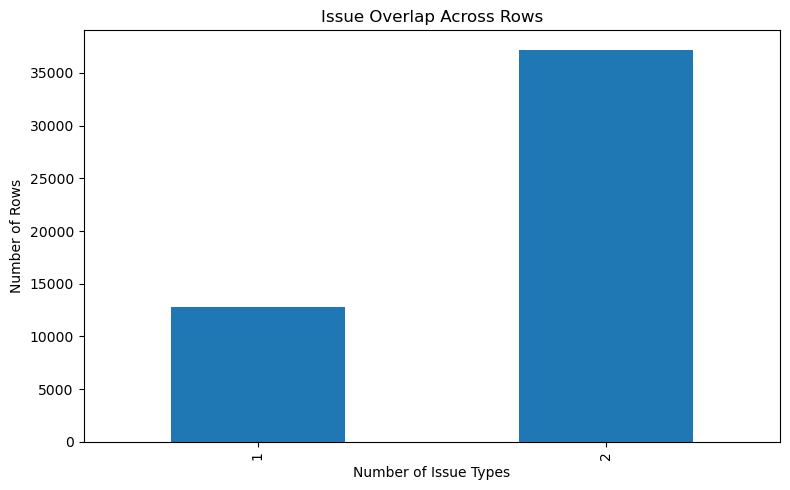

In [6]:

# ============================================================
# 10. ISSUE OVERLAP
# ============================================================

def analyze_issue_overlap(data, outliers, categories):
    flags = pd.DataFrame(index=data.index)

    # Null issue
    flags["Has_Null"] = data.isnull().any(axis=1)

    # Outlier issue
    outlier_rows = pd.Series(
        False,
        index=data.index,
        dtype=bool
    )

    if outliers is not None and "Column" in outliers.columns:
        for _, row in outliers.iterrows():
            column = row["Column"]

            if column not in data.columns:
                continue

            values = pd.to_numeric(
                data[column],
                errors="coerce"
            )

            lower = row["Lower_Bound"]
            upper = row["Upper_Bound"]

            if pd.notna(lower) and pd.notna(upper):
                outlier_rows |= (
                    values.notna() &
                    ((values < lower) | (values > upper))
                )

    flags["Has_Potential_Outlier"] = outlier_rows

    # Whitespace issue
    whitespace_rows = pd.Series(
        False,
        index=data.index,
        dtype=bool
    )

    if categories is not None and "Column" in categories.columns:
        for column in categories["Column"].dropna().unique():
            if column not in data.columns:
                continue

            values = data[column].astype("string")

            whitespace_rows |= (
                values.notna() &
                values.ne(values.str.strip())
            )

    flags["Has_Whitespace"] = whitespace_rows

    flags["Total_Issue_Types"] = flags[
        [
            "Has_Null",
            "Has_Potential_Outlier",
            "Has_Whitespace"
        ]
    ].sum(axis=1)

    return flags

issue_flags = analyze_issue_overlap(
    df,
    outlier_report,
    category_report
)

issue_flags.to_csv(
    os.path.join(REPORT_DIR, "Issue_Overlap.csv"),
    index=False
)

print("\nIssue Counts:")
display(
    issue_flags[
        ["Has_Null", "Has_Potential_Outlier", "Has_Whitespace"]
    ].sum()
)

plt.figure(figsize=(8, 5))

issue_counts = (
    issue_flags["Total_Issue_Types"]
    .value_counts()
    .sort_index()
)

if not issue_counts.empty:
    issue_counts.plot(kind="bar")
    plt.title("Issue Overlap Across Rows")
    plt.xlabel("Number of Issue Types")
    plt.ylabel("Number of Rows")
else:
    plt.text(0.5, 0.5, "No Rows to Analyze",
             ha="center", va="center")
    plt.axis("off")

plt.tight_layout()
plt.savefig(
    os.path.join(BEFORE_DIR, "Issue_Overlap.png"),
    dpi=160
)
plt.show()
plt.close()


Exact Duplicate Columns:


,Column_1,Column_2
0,deferral_term,hardship_length


Highly Correlated Columns:


,Column_1,Column_2,Correlation
0,loan_amnt,funded_amnt,0.999871
1,loan_amnt,funded_amnt_inv,0.999146
2,funded_amnt,funded_amnt_inv,0.999296
3,fico_range_low,fico_range_high,1.000000
4,open_acc,num_sats,0.999035
5,out_prncp,out_prncp_inv,0.999999
6,total_pymnt,total_pymnt_inv,0.999376
7,sec_app_fico_range_low,sec_app_fico_range_high,1.000000
8,hardship_amount,orig_projected_additional_accrued_interest,1.000000


Numeric Columns: 113

Correlation Analysis Completed

Strong Correlations:


,Column_1,Column_2,Correlation
6118,sec_app_fico_range_low,sec_app_fico_range_high,1.000000
6294,hardship_amount,orig_projected_additional_accrued_interest,1.000000
972,fico_range_low,fico_range_high,1.000000
1957,out_prncp,out_prncp_inv,0.999999
112,loan_amnt,funded_amnt,0.999871
2142,total_pymnt,total_pymnt_inv,0.999376
223,funded_amnt,funded_amnt_inv,0.999296
113,loan_amnt,funded_amnt_inv,0.999146
1540,open_acc,num_sats,0.999035
5472,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.984477



Near-Zero Correlations:


,Column_1,Column_2,Correlation
4613,inq_last_12m,hardship_last_payment_amount,-0.049980
455,int_rate,total_acc,-0.049902
5975,pub_rec_bankruptcies,settlement_percentage,-0.049892
3966,mths_since_rcnt_il,sec_app_revol_util,0.049864
3944,mths_since_rcnt_il,num_op_rev_tl,-0.049847
...,...,...,...
2619,recoveries,delinq_amnt,-0.000033
4002,total_bal_il,mths_since_recent_bc,-0.000032
2704,collection_recovery_fee,delinq_amnt,0.000030
1487,open_acc,total_rec_late_fee,-0.000022



Excel Report Saved: G:\DEPI\Projects\Project\DEPI-ITC-ONL5-DA-Team3-G3-Projects\FinalProject\docs\Data Cleaning\Accepted\Correlation_Matrix.xlsx


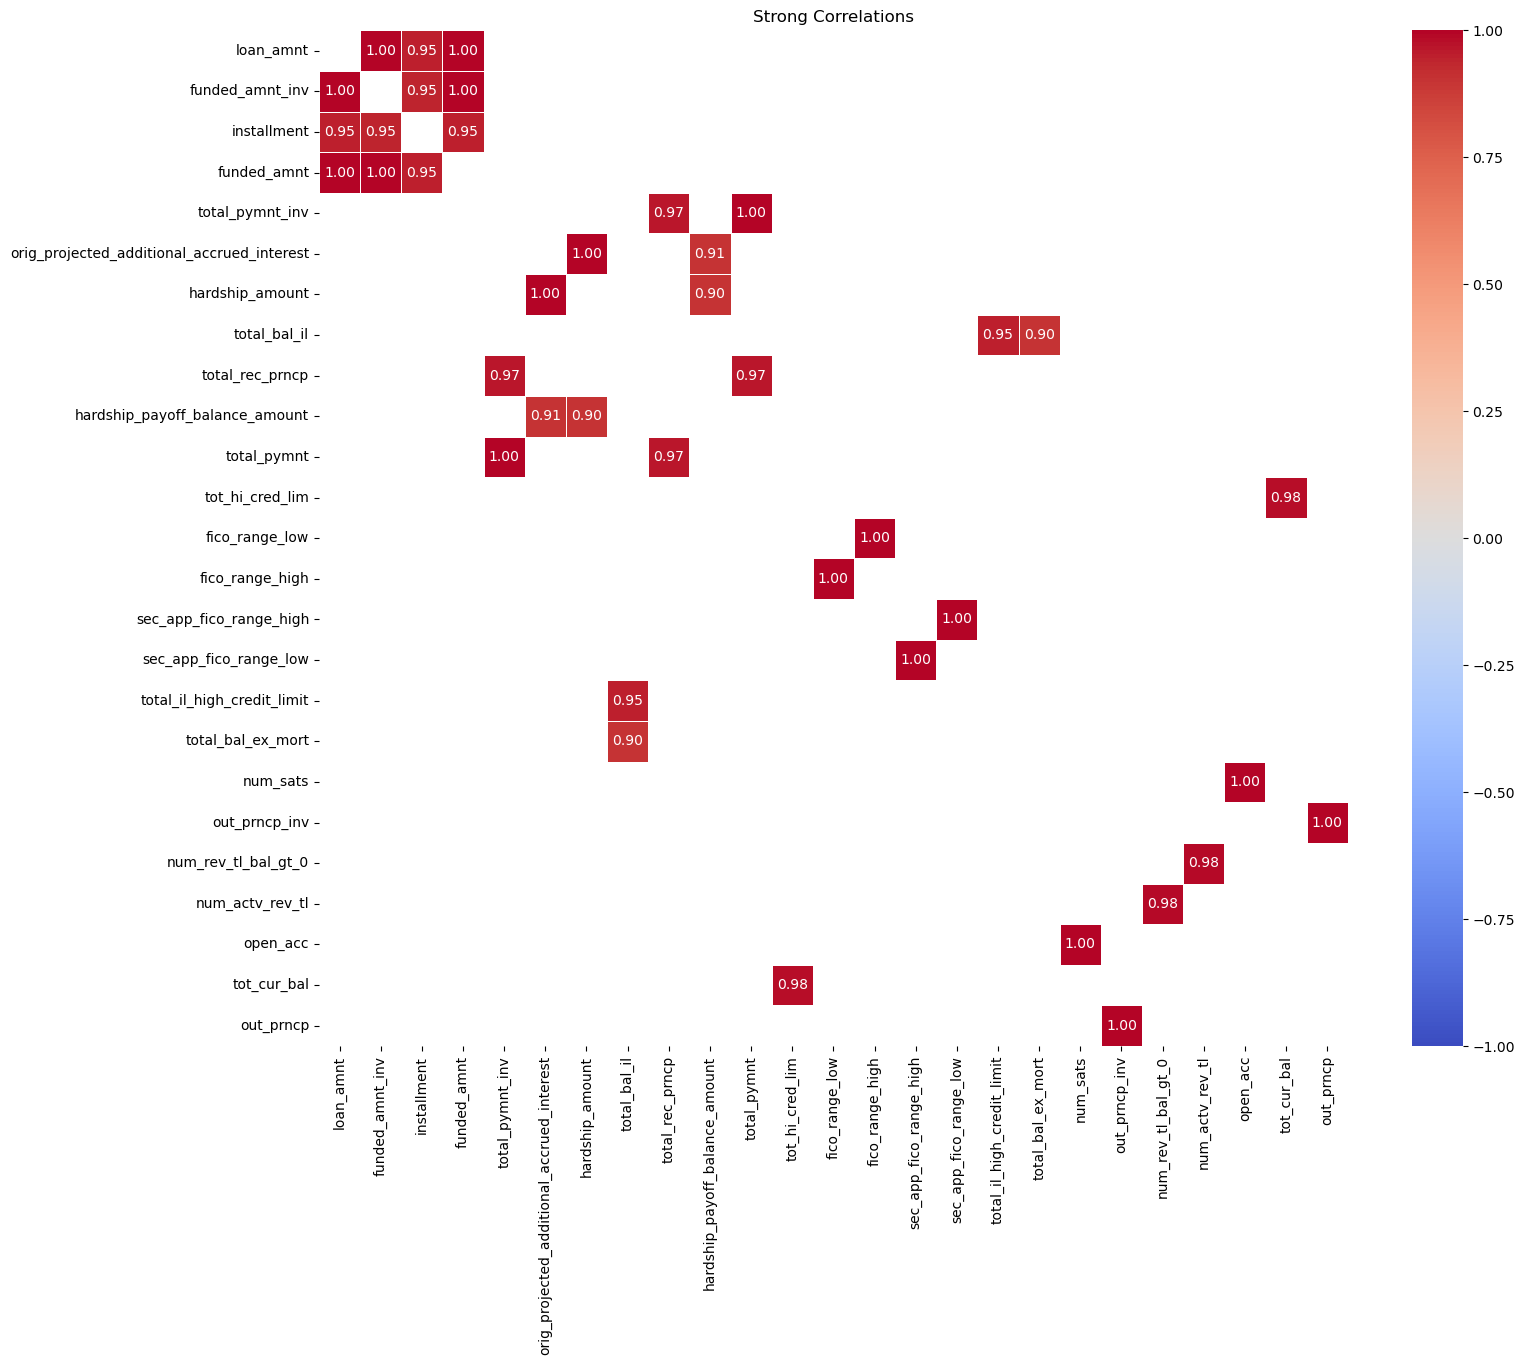

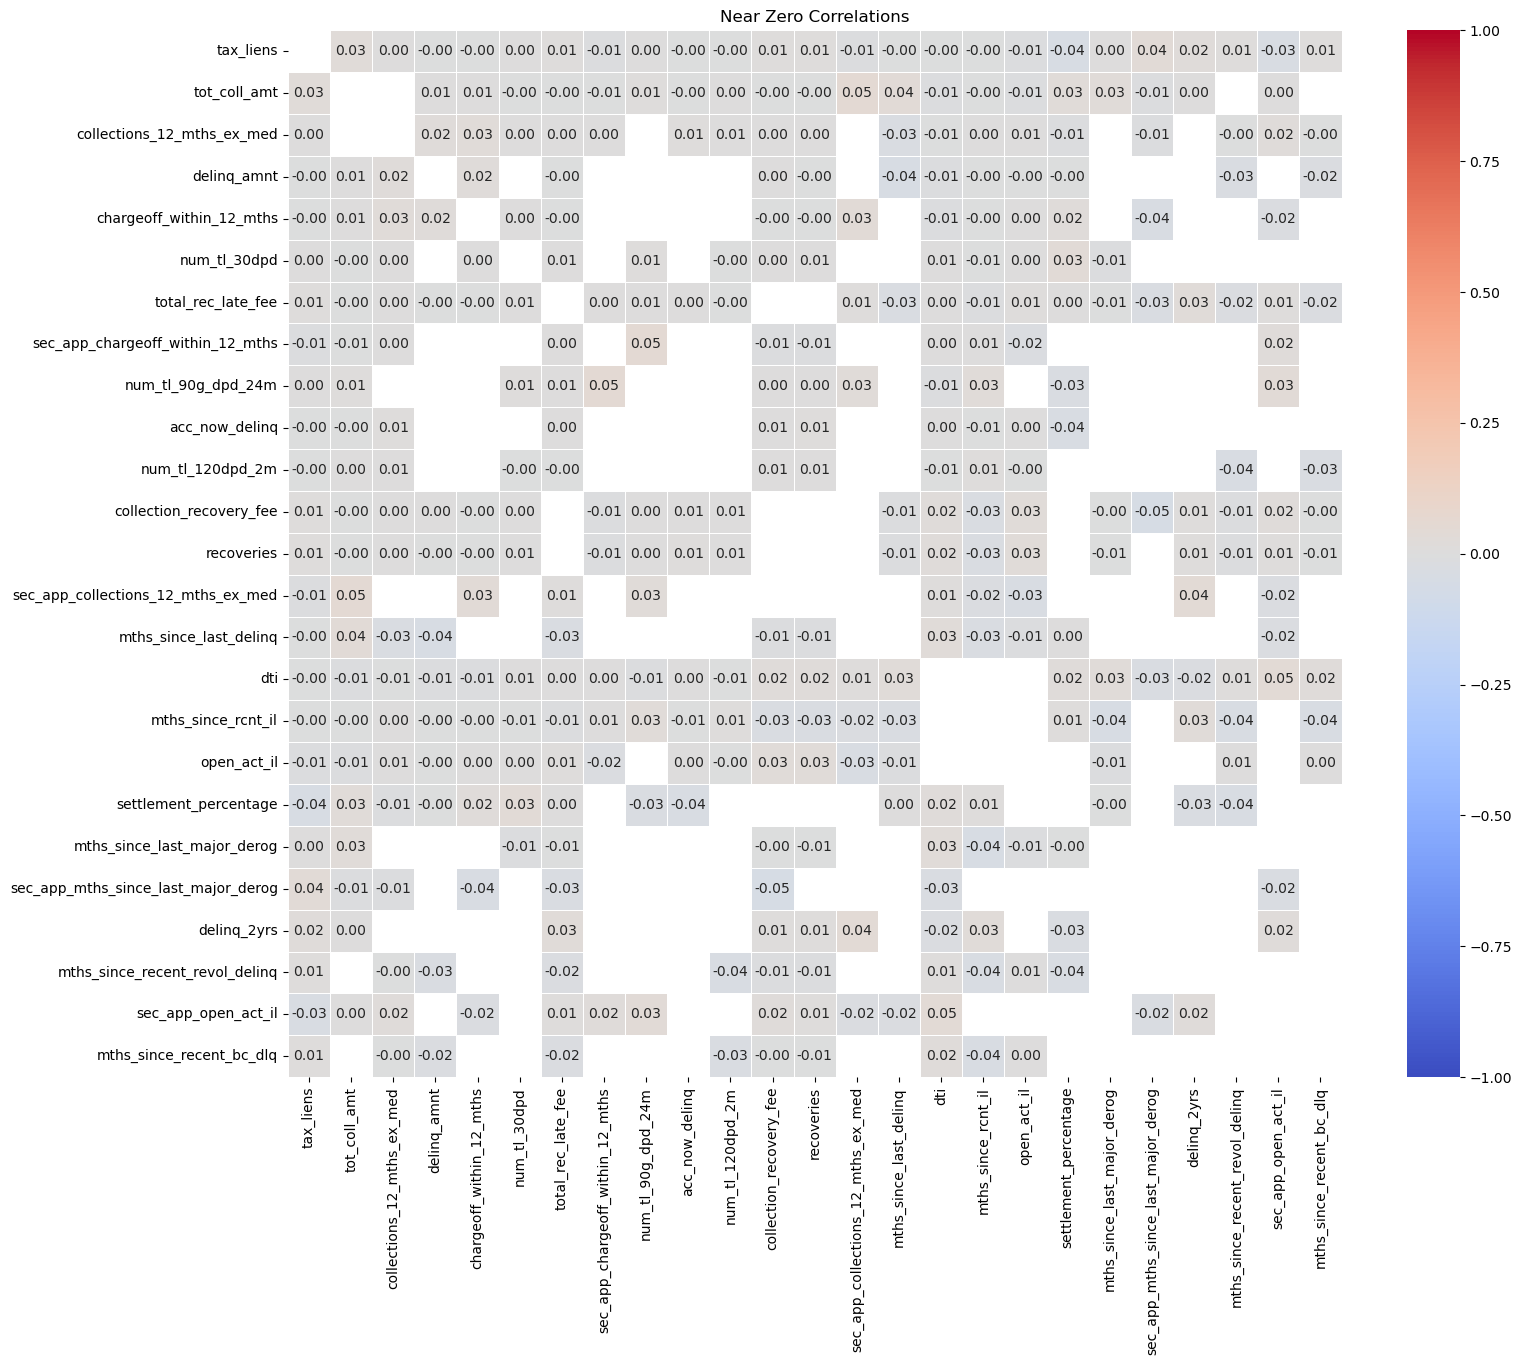

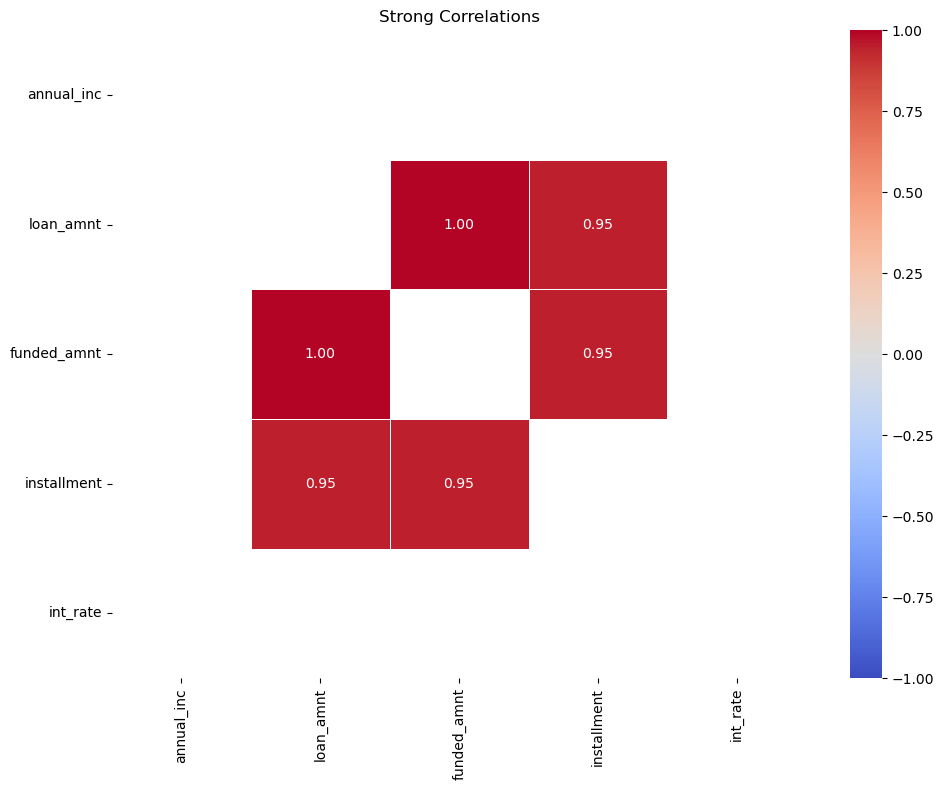

In [7]:

# ============================================================
# 11. REDUNDANT COLUMNS
# ============================================================

def find_redundant_columns(data):
    exact_duplicates = []
    highly_correlated = []

    # Exact duplicate columns
    for col1, col2 in combinations(data.columns, 2):
        if data[col1].equals(data[col2]):
            exact_duplicates.append({
                "Column_1": col1,
                "Column_2": col2
            })

    # Highly correlated numeric columns
    numeric = data.select_dtypes(include=[np.number])

    if numeric.shape[1] >= 2:
        correlation = numeric.corr().abs()
        columns = list(correlation.columns)

        for i, col1 in enumerate(columns):
            for col2 in columns[i + 1:]:
                value = correlation.loc[col1, col2]

                if pd.notna(value) and value >= 0.999:
                    highly_correlated.append({
                        "Column_1": col1,
                        "Column_2": col2,
                        "Correlation": value
                    })

    return (
        pd.DataFrame(
            exact_duplicates,
            columns=["Column_1", "Column_2"]
        ),
        pd.DataFrame(
            highly_correlated,
            columns=["Column_1", "Column_2", "Correlation"]
        )
    )

exact_duplicates, correlated_columns = find_redundant_columns(df)

exact_duplicates.to_csv(
    os.path.join(REPORT_DIR, "Exact_Duplicate_Columns.csv"),
    index=False
)

correlated_columns.to_csv(
    os.path.join(REPORT_DIR, "Highly_Correlated_Columns.csv"),
    index=False
)

print("Exact Duplicate Columns:")
display(exact_duplicates)

print("Highly Correlated Columns:")
display(correlated_columns)


# ============================================================
# 11.1 CORRELATION ANALYSIS
# ============================================================

def analyze_correlations(data, report_dir):

    # Numeric columns only
    numeric = data.select_dtypes(include=[np.number])

    print(f"Numeric Columns: {numeric.shape[1]}")

    # Calculate correlation matrix
    correlation = numeric.corr(
        method="pearson",
        min_periods=100
    )

    # Get unique column pairs (exclude diagonal and duplicates)
    row_indices, col_indices = np.triu_indices(
        len(correlation.columns), k=1
    )

    values = correlation.to_numpy()[
        row_indices, col_indices
    ]

    correlation_pairs = pd.DataFrame({
        "Column_1": correlation.columns[row_indices],
        "Column_2": correlation.columns[col_indices],
        "Correlation": values
    }).dropna()

    # Sort by absolute correlation
    correlation_pairs["Absolute_Correlation"] = (
        correlation_pairs["Correlation"].abs()
    )

    correlation_pairs = correlation_pairs.sort_values(
        "Absolute_Correlation",
        ascending=False
    )

    # Strong correlations
    strong_correlations = correlation_pairs[
        (correlation_pairs["Correlation"] >= 0.90) |
        (correlation_pairs["Correlation"] <= -0.90)
    ].copy()

    # Near-zero correlations
    near_zero_correlations = correlation_pairs[
        correlation_pairs["Correlation"].between(-0.05, 0.05)
    ].copy()

    # Remove helper column from exported reports
    correlation_pairs = correlation_pairs.drop(
        columns=["Absolute_Correlation"]
    )

    # Export Excel workbook
    excel_path = os.path.join(
        report_dir, "Correlation_Matrix.xlsx"
    )

    with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

        correlation.to_excel(
            writer,
            sheet_name="Correlation_Matrix"
        )

        correlation_pairs.to_excel(
            writer,
            sheet_name="All_Correlation_Pairs",
            index=False
        )

        strong_correlations.drop(
            columns=["Absolute_Correlation"]
        ).to_excel(
            writer,
            sheet_name="Strong_Correlations",
            index=False
        )

        near_zero_correlations.drop(
            columns=["Absolute_Correlation"]
        ).to_excel(
            writer,
            sheet_name="Near_Zero",
            index=False
        )

    print("\nCorrelation Analysis Completed")

    print("\nStrong Correlations:")
    display(strong_correlations.drop(
        columns=["Absolute_Correlation"]
    ))

    print("\nNear-Zero Correlations:")
    display(near_zero_correlations.drop(
        columns=["Absolute_Correlation"]
    ))

    print(f"\nExcel Report Saved: {excel_path}")

    return (
        correlation,
        correlation_pairs,
        strong_correlations,
        near_zero_correlations
    )


correlation, correlation_pairs, strong_correlations, near_zero_correlations = (
    analyze_correlations(df, REPORT_DIR)
)


# ============================================================
# 11.2 FILTERED CORRELATION HEATMAPS
# ============================================================

def plot_filtered_heatmap(
    correlation,
    mode="strong",
    threshold=0.90,
    focus_columns=None,
    max_columns=25
):

    # Identify qualifying correlations
    if mode == "strong":
        condition = (
            (correlation >= threshold) |
            (correlation <= -threshold)
        )

    elif mode == "near_zero":
        condition = correlation.abs() <= threshold

    else:
        raise ValueError(
            "Mode must be 'strong' or 'near_zero'"
        )

    # Exclude diagonal
    np.fill_diagonal(condition.values, False)

    # Select specific columns or identify them automatically
    if focus_columns is not None:

        selected = [
            col for col in focus_columns
            if col in correlation.columns
        ]

    else:

        qualifying_pairs = condition.sum(axis=1)

        selected = qualifying_pairs[
            qualifying_pairs > 0
        ].sort_values(
            ascending=False
        ).head(max_columns).index.tolist()

    if len(selected) < 2:
        print("Not enough columns found for this heatmap.")
        return

    # Limit to selected columns
    filtered = correlation.loc[selected, selected].copy()

    # Hide correlations that don't meet the condition
    filtered_condition = condition.loc[selected, selected]

    filtered = filtered.where(filtered_condition)

    # Plot heatmap
    plt.figure(
        figsize=(
            max(10, len(selected) * 0.65),
            max(8, len(selected) * 0.55)
        )
    )

    sns.heatmap(
        filtered,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        mask=filtered.isna()
    )

    plt.title(
        f"{mode.replace('_', ' ').title()} Correlations"
    )

    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    plt.close()


# Strong positive / negative correlations
plot_filtered_heatmap(
    correlation,
    mode="strong",
    threshold=0.90
)

# Near-zero correlations
plot_filtered_heatmap(
    correlation,
    mode="near_zero",
    threshold=0.05
)

# Example: Investigate specific columns
plot_filtered_heatmap(
    correlation,
    mode="strong",
    threshold=0.90,
    focus_columns=[
        "annual_inc",
        "loan_amnt",
        "funded_amnt",
        "installment",
        "int_rate"
    ]
)



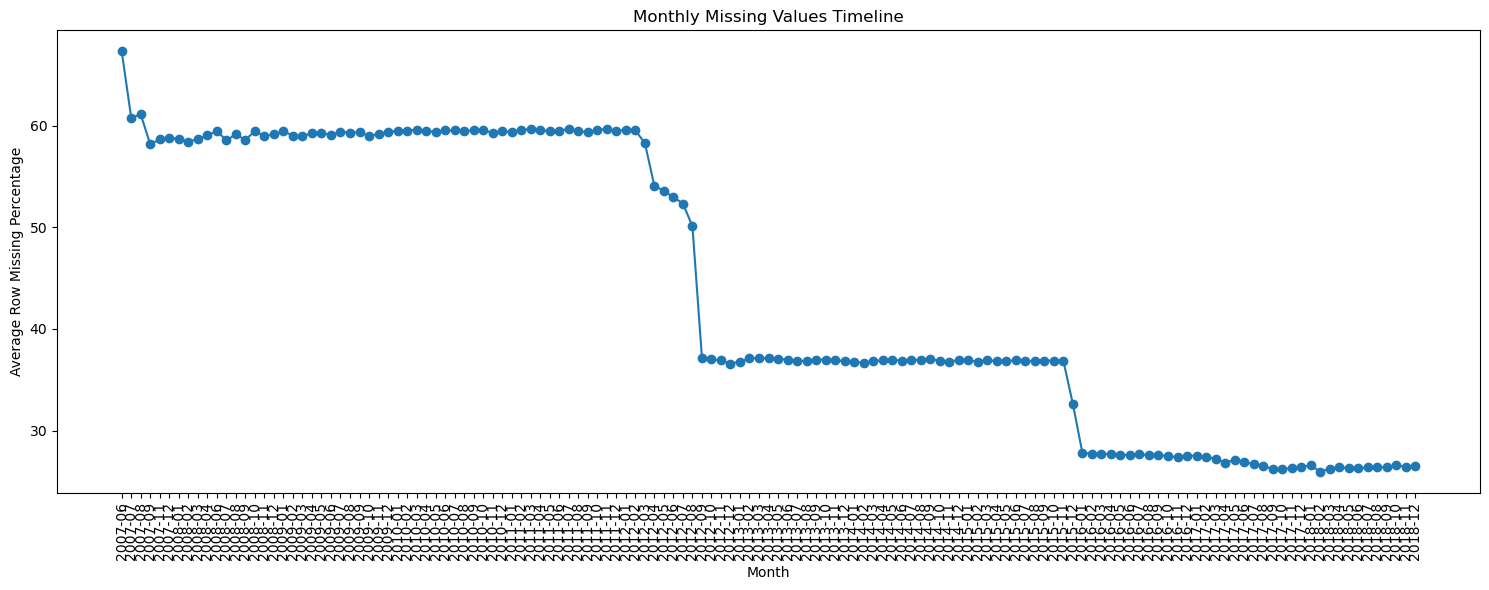

,Year,Row_Count
0,2007,16
1,2008,48
2,2009,115
3,2010,279
4,2011,486
5,2012,1218
6,2013,2935
7,2014,5158
8,2015,9274
9,2016,9673


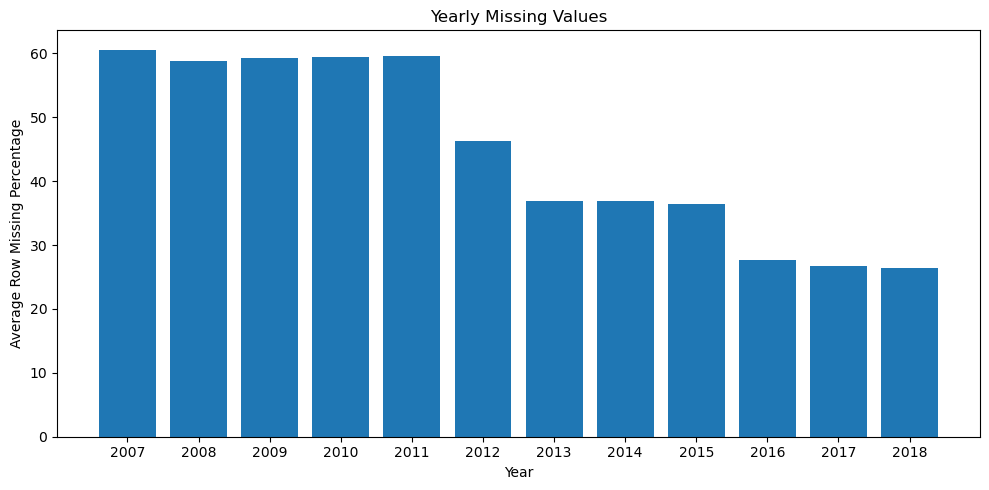

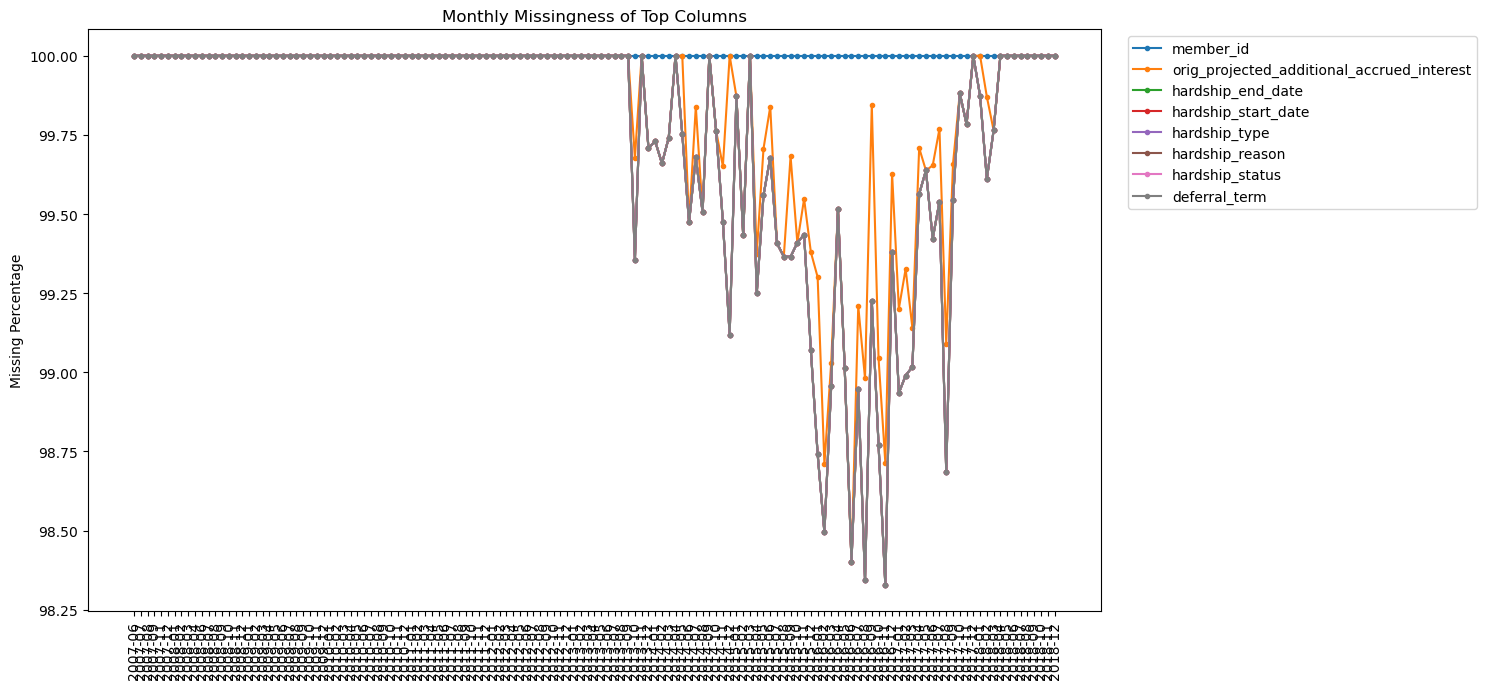

Valid dates: 49999
Invalid or missing dates: 1


In [8]:

# ============================================================
# OBJECTIVE 2: TIMELINE ANALYSIS
# ============================================================

# ============================================================
# 12. DATE ANALYSIS
# ============================================================

DATE_COLUMN = "issue_d"

def parse_dates(series):
    text_values = series.astype("string").str.strip()

    dates = pd.to_datetime(
        text_values,
        format="%b-%Y",
        errors="coerce"
    )

    remaining = dates.isna() & text_values.notna()

    if remaining.any():
        dates.loc[remaining] = pd.to_datetime(
            text_values.loc[remaining],
            errors="coerce"
        )

    return dates

if DATE_COLUMN in df.columns:
    dates = parse_dates(df[DATE_COLUMN])
    valid_dates = dates.notna()

    if valid_dates.any():
        timeline_data = df.loc[valid_dates].copy()

        timeline_data["Year"] = (
            dates.loc[valid_dates].dt.year.to_numpy()
        )

        timeline_data["Month"] = (
            dates.loc[valid_dates]
            .dt.to_period("M")
            .astype(str)
            .to_numpy()
        )

        timeline_data["_Row_Missing_Percentage"] = (
            timeline_data.isnull().mean(axis=1) * 100
        )

        # Monthly missingness
        monthly_nulls = (
            timeline_data.groupby("Month")[
                "_Row_Missing_Percentage"
            ]
            .mean()
            .reset_index(name="Missing_Percentage")
        )

        monthly_nulls.to_csv(
            os.path.join(REPORT_DIR, "Monthly_Nulls_Timeline.csv"),
            index=False
        )

        plt.figure(figsize=(15, 6))
        plt.plot(
            monthly_nulls["Month"],
            monthly_nulls["Missing_Percentage"],
            marker="o"
        )
        plt.xticks(rotation=90)
        plt.title("Monthly Missing Values Timeline")
        plt.xlabel("Month")
        plt.ylabel("Average Row Missing Percentage")
        plt.tight_layout()
        plt.savefig(
            os.path.join(BEFORE_DIR, "Monthly_Nulls_Timeline.png"),
            dpi=160
        )
        plt.show()
        plt.close()

        # Yearly row counts
        yearly_counts = (
            timeline_data.groupby("Year")
            .size()
            .reset_index(name="Row_Count")
        )

        yearly_counts.to_csv(
            os.path.join(REPORT_DIR, "Yearly_Row_Counts.csv"),
            index=False
        )

        display(yearly_counts)

        # Yearly missingness
        yearly_nulls = (
            timeline_data.groupby("Year")[
                "_Row_Missing_Percentage"
            ]
            .mean()
            .reset_index(name="Missing_Percentage")
        )

        plt.figure(figsize=(10, 5))
        plt.bar(
            yearly_nulls["Year"].astype(str),
            yearly_nulls["Missing_Percentage"]
        )
        plt.title("Yearly Missing Values")
        plt.xlabel("Year")
        plt.ylabel("Average Row Missing Percentage")
        plt.tight_layout()
        plt.savefig(
            os.path.join(BEFORE_DIR, "Yearly_Nulls.png"),
            dpi=160
        )
        plt.show()
        plt.close()

        # Top missing columns over time
        top_missing_columns = (
            df.isnull().mean()
            .sort_values(ascending=False)
            .head(8)
            .index.tolist()
        )

        monthly_column_nulls = (
            timeline_data.groupby("Month")[top_missing_columns]
            .apply(lambda x: x.isnull().mean() * 100)
        )

        plt.figure(figsize=(15, 7))

        for column in top_missing_columns:
            plt.plot(
                monthly_column_nulls.index,
                monthly_column_nulls[column],
                marker=".",
                label=column
            )

        plt.xticks(rotation=90)
        plt.title("Monthly Missingness of Top Columns")
        plt.ylabel("Missing Percentage")
        plt.legend(
            bbox_to_anchor=(1.02, 1),
            loc="upper left"
        )
        plt.tight_layout()
        plt.savefig(
            os.path.join(BEFORE_DIR, "Top_Columns_Timeline.png"),
            dpi=160
        )
        plt.show()
        plt.close()

        print("Valid dates:", int(valid_dates.sum()))
        print("Invalid or missing dates:", int((~valid_dates).sum()))

    else:
        print("No valid dates found in:", DATE_COLUMN)

else:
    print("Date column not found:", DATE_COLUMN)


In [9]:

# ============================================================
# CLEANING PHASE
# ============================================================

# ============================================================
# 13. DOCUMENTED CLEANING RULES
# ============================================================

# لا توجد قواعد حذف أو تعبئة أو تعديل معتمدة تلقائيًا.
# أضف القواعد فقط بعد مراجعة خطة المشروع.

APPROVED_RULES = [
    # مثال:
    # {
    #     "action": "strip_whitespace",
    #     "column": "some_column",
    #     "reason": "Documented and approved cleaning rule"
    # },

    # مثال:
    # {
    #     "action": "drop_exact_duplicate_rows",
    #     "reason": "Confirmed exact duplicate records"
    # }
]

# ============================================================
# 14. APPLY APPROVED RULES
# ============================================================

def apply_cleaning_rules(data, rules):
    cleaned = data.copy(deep=True)
    change_log = []

    for rule_number, rule in enumerate(rules, start=1):
        if "action" not in rule:
            raise ValueError(
                f"Rule {rule_number} is missing its action."
            )

        action = rule["action"]
        reason = str(rule.get("reason", "")).strip()

        if not reason:
            raise ValueError(
                "Every cleaning rule must have a documented reason."
            )

        if action == "strip_whitespace":
            column = rule.get("column")

            if column not in cleaned.columns:
                raise KeyError(column)

            is_text = (
                pd.api.types.is_object_dtype(cleaned[column])
                or pd.api.types.is_string_dtype(cleaned[column])
                or isinstance(cleaned[column].dtype, pd.CategoricalDtype)
            )

            if not is_text:
                raise TypeError(
                    f"strip_whitespace requires a text column: {column}"
                )

            before = cleaned[column].copy()
            mask = cleaned[column].notna()

            cleaned.loc[mask, column] = (
                cleaned.loc[mask, column]
                .astype("string")
                .str.strip()
            )

            changed = int(
                (
                    before.astype("string").fillna("<NULL>")
                    !=
                    cleaned[column].astype("string").fillna("<NULL>")
                ).sum()
            )

            change_log.append({
                "Rule_Number": rule_number,
                "Column": column,
                "Action": action,
                "Changed_Cells": changed,
                "Rows_Before": len(cleaned),
                "Rows_After": len(cleaned),
                "Reason": reason
            })

        elif action == "drop_exact_duplicate_rows":
            rows_before = len(cleaned)
            cleaned = cleaned.drop_duplicates().copy()

            change_log.append({
                "Rule_Number": rule_number,
                "Column": "ALL",
                "Action": action,
                "Changed_Cells": 0,
                "Rows_Before": rows_before,
                "Rows_After": len(cleaned),
                "Reason": reason
            })

        else:
            raise ValueError(
                f"Unsupported cleaning action: {action}"
            )

    log_columns = [
        "Rule_Number",
        "Column",
        "Action",
        "Changed_Cells",
        "Rows_Before",
        "Rows_After",
        "Reason"
    ]

    return cleaned, pd.DataFrame(
        change_log,
        columns=log_columns
    )

# Remove columns whose missingness is above the lower of:
# (1) the average missing percentage across all original columns, or
# (2) the fixed 39% ceiling.
column_missing_pct = df.isna().mean() * 100
average_missing_pct = float(column_missing_pct.mean())
missingness_cutoff = min(average_missing_pct, 39.0)
columns_to_drop = column_missing_pct[column_missing_pct > missingness_cutoff].index.tolist()

cleaning_base = df.drop(columns=columns_to_drop).copy(deep=True)

cleaned_df, cleaning_log = apply_cleaning_rules(
    cleaning_base,
    APPROVED_RULES
)

threshold_report = pd.DataFrame({
    "Column": column_missing_pct.index,
    "Missing_Percentage": column_missing_pct.values,
    "Average_Missing_Percentage": average_missing_pct,
    "Applied_Cutoff_Percentage": missingness_cutoff,
    "Removed": [c in columns_to_drop for c in column_missing_pct.index]
}).sort_values("Missing_Percentage", ascending=False)

threshold_report.to_csv(
    os.path.join(REPORT_DIR, "Missingness_Column_Removal_Report.csv"),
    index=False
)

if columns_to_drop:
    threshold_log = pd.DataFrame([{
        "Rule_Number": 0,
        "Column": ", ".join(columns_to_drop),
        "Action": "drop_high_missing_columns",
        "Changed_Cells": 0,
        "Rows_Before": len(df),
        "Rows_After": len(cleaned_df),
        "Reason": (
            f"Removed columns with missingness above {missingness_cutoff:.2f}%; "
            f"average missingness was {average_missing_pct:.2f}% and the cap is 39%."
        )
    }])
    cleaning_log = pd.concat([threshold_log, cleaning_log], ignore_index=True)

cleaned_df.to_csv(
    CLEANED_FILE,
    index=False
)

cleaning_log.to_csv(
    os.path.join(REPORT_DIR, "Cleaning_Log.csv"),
    index=False
)

display(cleaning_log)


,Rule_Number,Column,Action,Changed_Cells,Rows_Before,Rows_After,Reason
0,0,"member_id, desc, mths_since_last_delinq, mths_...",drop_high_missing_columns,0,50000,50000,Removed columns with missingness above 31.79%;...


In [10]:

# ============================================================
# 15. BEFORE AND AFTER COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Null Cells",
        "Duplicate Rows"
    ],
    "Before": [
        len(df),
        df.shape[1],
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum())
    ],
    "After": [
        len(cleaned_df),
        cleaned_df.shape[1],
        int(cleaned_df.isnull().sum().sum()),
        int(cleaned_df.duplicated().sum())
    ]
})

display(comparison)

comparison.to_csv(
    os.path.join(REPORT_DIR, "Before_After_Comparison.csv"),
    index=False
)

# ============================================================
# 16. FINAL VALIDATION
# ============================================================

def validate_data(data):
    return {
        "Rows": int(len(data)),
        "Columns": int(data.shape[1]),
        "Null_Cells": int(data.isnull().sum().sum()),
        "Duplicate_Rows": int(data.duplicated().sum()),
        "Completely_Empty_Columns": int(data.isnull().all().sum()),
        "Constant_Columns": int(
            (data.nunique(dropna=False) <= 1).sum()
        )
    }

validation_results = pd.DataFrame([
    {
        "Dataset": "Before",
        **validate_data(df)
    },
    {
        "Dataset": "After",
        **validate_data(cleaned_df)
    }
])

display(validation_results)

validation_results.to_csv(
    os.path.join(REPORT_DIR, "Validation_Results.csv"),
    index=False
)


,Metric,Before,After
0,Rows,50000,50000
1,Columns,151,93
2,Null Cells,2400197,68186
3,Duplicate Rows,0,0


,Dataset,Rows,Columns,Null_Cells,Duplicate_Rows,Completely_Empty_Columns,Constant_Columns
0,Before,50000,151,2400197,0,1,1
1,After,50000,93,68186,0,0,0
